# Heart Disease Risk Prediction & Patient Segmentation

### Logistic Regression + K-Means Clustering | Healthcare Machine Learning Portfolio Project

This project uses the **Framingham Heart Study teaching dataset** to explore two complementary machine-learning tasks:

1. **Supervised learning:** estimate whether a patient is at elevated risk of coronary heart disease (CHD) within 10 years using Logistic Regression.
2. **Unsupervised learning:** identify groups of patients with similar risk-factor profiles using K-Means clustering.

The notebook is designed as an **educational portfolio project**, not a clinical diagnostic tool.

## Why this version is portfolio-ready

The original assignment achieved high overall accuracy, but the positive CHD class is much smaller than the negative class. In a healthcare screening context, accuracy alone can hide poor detection of higher-risk patients. This version therefore:

- prevents preprocessing leakage by fitting imputers/scalers on training data only;
- uses a stratified train/validation/test design;
- compares an ordinary Logistic Regression baseline with a class-balanced model;
- tunes the decision threshold on validation data using **F2 score**, which gives more weight to recall;
- reports **sensitivity, specificity, balanced accuracy, ROC-AUC and PR-AUC**;
- selects the K-Means cluster count using **silhouette score** rather than choosing `k` arbitrarily;
- interprets clusters as patient segments instead of treating K-Means as a supervised classifier;
- includes reproducibility, limitations and model-saving steps.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

print('Environment ready.')

Environment ready.


## 2. Load the dataset

The code first looks for a local copy of `framingham.csv`. If it is not found, it attempts to load a public mirror of the teaching dataset. For a GitHub repository, the recommended structure is:

```text
heart-disease-ml-portfolio/
├── HEART_DISEASE_PREDICTION_PORTFOLIO.ipynb
├── README.md
├── requirements.txt
└── data/
    └── framingham.csv   # optional local copy
```

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/Natassha/streamlit_fhs/main/framingham.csv'
local_candidates = [
    Path('data/framingham.csv'),
    Path('framingham.csv'),
    Path('/content/framingham.csv'),
]

for candidate in local_candidates:
    if candidate.exists():
        df = pd.read_csv(candidate)
        data_source = str(candidate)
        break
else:
    df = pd.read_csv(DATA_URL)
    data_source = DATA_URL

print(f'Data source: {data_source}')
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head()

Data source: https://raw.githubusercontent.com/Natassha/streamlit_fhs/main/framingham.csv
Shape: 4,240 rows × 16 columns


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.000,0,0.000,0.000,0,0,0,195.000,106.000,70.000,26.970,80.000,77.000,0
1,0,46,2.000,0,0.000,0.000,0,0,0,250.000,121.000,81.000,28.730,95.000,76.000,0
2,1,48,1.000,1,20.000,0.000,0,0,0,245.000,127.500,80.000,25.340,75.000,70.000,0
3,0,61,3.000,1,30.000,0.000,0,1,0,225.000,150.000,95.000,28.580,65.000,103.000,1
4,0,46,3.000,1,23.000,0.000,0,0,0,285.000,130.000,84.000,23.100,85.000,85.000,0


## 3. Data dictionary

| Feature | Meaning |
|---|---|
| `male` | Sex indicator in the teaching dataset |
| `age` | Age in years |
| `education` | Education category |
| `currentSmoker` | Current smoking status |
| `cigsPerDay` | Cigarettes smoked per day |
| `BPMeds` | Blood-pressure medication indicator |
| `prevalentStroke` | History of stroke |
| `prevalentHyp` | Prevalent hypertension |
| `diabetes` | Diabetes indicator |
| `totChol` | Total cholesterol |
| `sysBP` | Systolic blood pressure |
| `diaBP` | Diastolic blood pressure |
| `BMI` | Body mass index |
| `heartRate` | Heart rate |
| `glucose` | Blood glucose |
| `TenYearCHD` | Target: 10-year CHD event indicator |

## 4. Data quality checks

In [3]:
print('Column types:')
display(df.dtypes.to_frame('dtype'))

quality = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': df.isna().mean().mul(100),
    'unique_values': df.nunique(),
}).sort_values('missing_pct', ascending=False)

print(f'Duplicate rows: {df.duplicated().sum():,}')
display(quality)

Column types:


,dtype
male,int64
age,int64
education,float64
currentSmoker,int64
cigsPerDay,float64
BPMeds,float64
prevalentStroke,int64
prevalentHyp,int64
diabetes,int64
totChol,float64


Duplicate rows: 0


,missing_count,missing_pct,unique_values
glucose,388,9.151,143
education,105,2.476,4
BPMeds,53,1.250,2
totChol,50,1.179,248
cigsPerDay,29,0.684,33
BMI,19,0.448,1364
heartRate,1,0.024,73
male,0,0.000,2
prevalentHyp,0,0.000,2
prevalentStroke,0,0.000,2


### Target balance

A model can appear accurate simply by predicting the majority class. Because this dataset is imbalanced, the positive-class recall and precision-recall metrics are especially important.

,count,percent
No CHD (0),3596,84.811
CHD (1),644,15.189


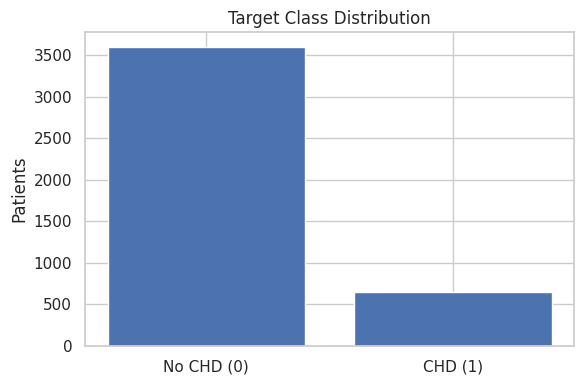

In [4]:
target_col = 'TenYearCHD'
class_counts = df[target_col].value_counts().sort_index()
class_pct = df[target_col].value_counts(normalize=True).sort_index().mul(100)

balance_table = pd.DataFrame({'count': class_counts, 'percent': class_pct})
balance_table.index = ['No CHD (0)', 'CHD (1)']
display(balance_table)

fig, ax = plt.subplots(figsize=(6,4))
ax.bar(balance_table.index, balance_table['count'])
ax.set_title('Target Class Distribution')
ax.set_ylabel('Patients')
plt.tight_layout()
plt.show()

## 5. Focused exploratory data analysis

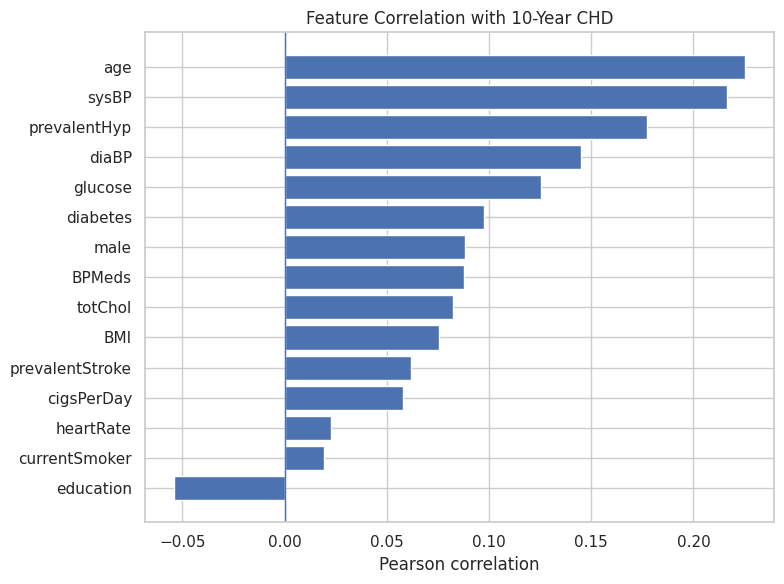

,correlation_with_CHD
age,0.225
sysBP,0.216
prevalentHyp,0.177
diaBP,0.145
glucose,0.126
diabetes,0.097
male,0.088
BPMeds,0.088
totChol,0.082
BMI,0.075


In [5]:
# Correlation with the target (numeric teaching dataset)
corr = df.corr(numeric_only=True)[target_col].drop(target_col).sort_values()

fig, ax = plt.subplots(figsize=(8,6))
ax.barh(corr.index, corr.values)
ax.axvline(0, linewidth=1)
ax.set_title('Feature Correlation with 10-Year CHD')
ax.set_xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

display(corr.sort_values(ascending=False).to_frame('correlation_with_CHD'))

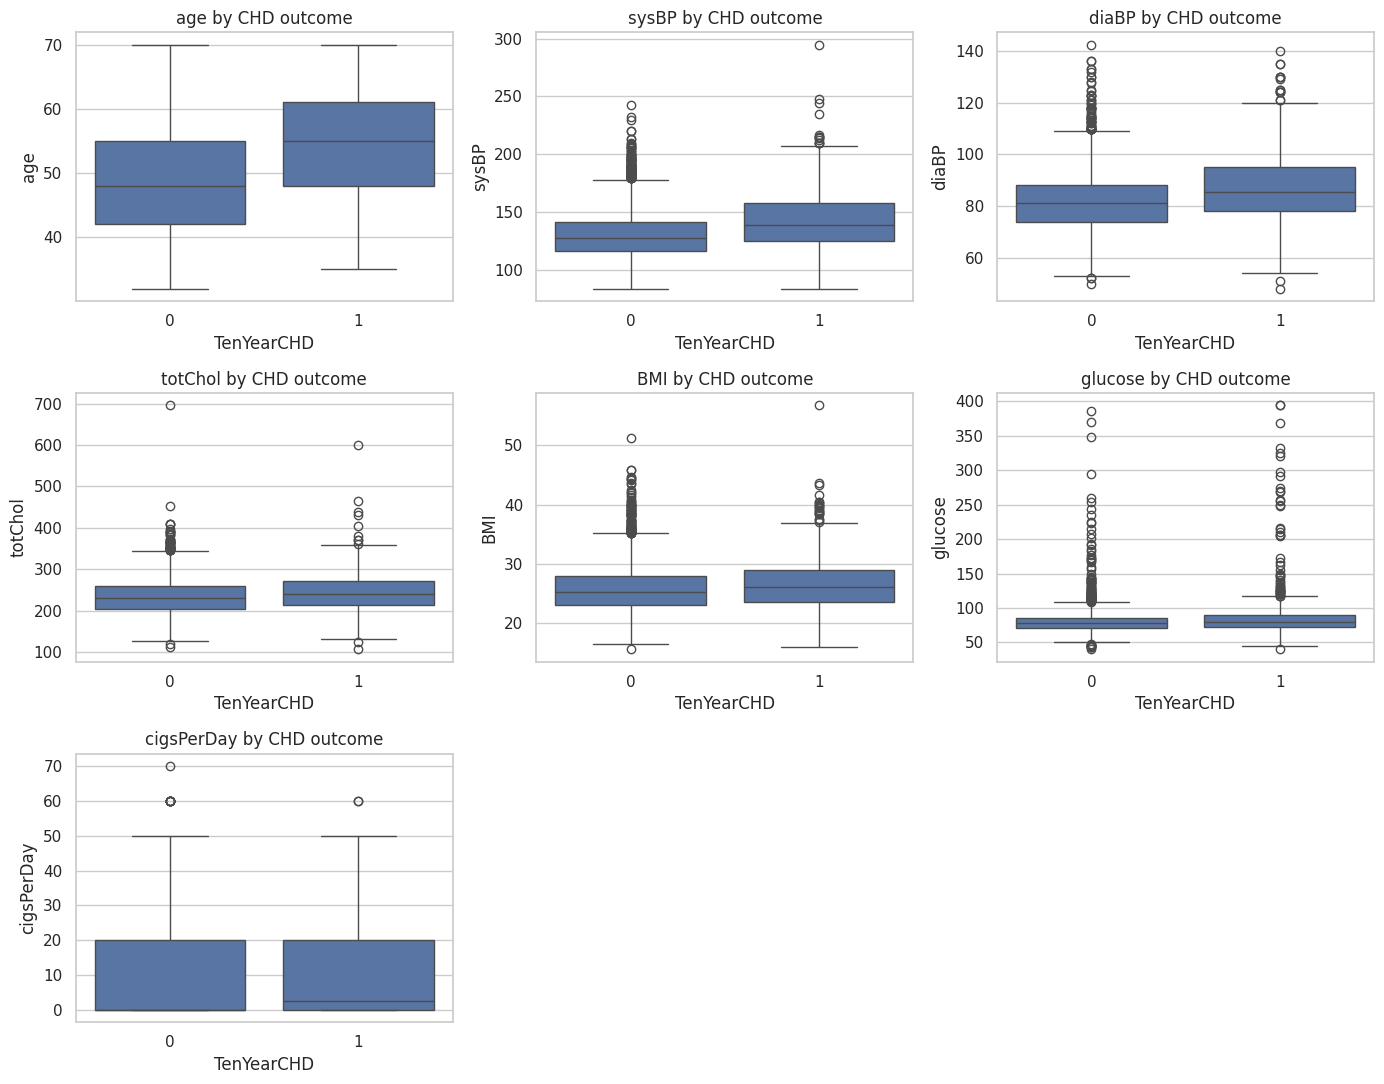

In [6]:
key_features = ['age', 'sysBP', 'diaBP', 'totChol', 'BMI', 'glucose', 'cigsPerDay']
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()

for ax, feature in zip(axes, key_features):
    sns.boxplot(data=df, x=target_col, y=feature, ax=ax)
    ax.set_title(f'{feature} by CHD outcome')
    ax.set_xlabel('TenYearCHD')

for ax in axes[len(key_features):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Train / validation / test split

The test set is held back until final evaluation. The validation set is used for threshold selection so the decision threshold is not tuned on the test data.

In [7]:
X = df.drop(columns=target_col)
y = df[target_col].astype(int)

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    'rows': [len(X_train), len(X_val), len(X_test)],
    'positive_rate': [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=['Train', 'Validation', 'Test'])
display(split_summary)

,rows,positive_rate
Train,2968,0.152
Validation,636,0.153
Test,636,0.151


## 7. Leakage-safe preprocessing pipeline

Missing values are imputed with training-set medians, and features are standardized. Both transformations are placed inside a scikit-learn `Pipeline`, so cross-validation never learns preprocessing statistics from validation folds.

In [8]:
def make_logistic_pipeline(class_weight=None, C=1.0):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ])

baseline_model = make_logistic_pipeline(class_weight=None)
baseline_model.fit(X_train, y_train)
print('Baseline pipeline fitted.')

Baseline pipeline fitted.


## 8. Baseline Logistic Regression

In [9]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp) if (tn + fp) else np.nan


def evaluate_binary_model(y_true, y_prob, threshold=0.50):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        'threshold': threshold,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall_sensitivity': recall_score(y_true, y_pred, zero_division=0),
        'specificity': specificity_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'f2': fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_prob),
        'pr_auc': average_precision_score(y_true, y_prob),
    }

baseline_test_prob = baseline_model.predict_proba(X_test)[:, 1]
baseline_metrics = evaluate_binary_model(y_test, baseline_test_prob, threshold=0.50)
display(pd.DataFrame([baseline_metrics], index=['Baseline LR']).T)

,Baseline LR
threshold,0.500
accuracy,0.852
balanced_accuracy,0.532
precision,0.583
recall_sensitivity,0.073
specificity,0.991
f1,0.130
f2,0.088
roc_auc,0.699
pr_auc,0.328


## 9. Class-balanced Logistic Regression with hyperparameter tuning

The class-balanced model increases the penalty for misclassifying the minority class. `C` is tuned using stratified 5-fold cross-validation on the training set, optimizing **average precision (PR-AUC)**.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

balanced_pipe = make_logistic_pipeline(class_weight='balanced')
param_grid = {'model__C': [0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]}

search = GridSearchCV(
    balanced_pipe,
    param_grid=param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    refit=True,
)
search.fit(X_train, y_train)

print('Best C:', search.best_params_['model__C'])
print(f'Best CV PR-AUC: {search.best_score_:.3f}')

Best C: 0.01
Best CV PR-AUC: 0.361


## 10. Tune the classification threshold for screening

A probability threshold of 0.50 is conventional, but it is not automatically optimal for an imbalanced screening task. Here, the threshold is chosen **only on the validation set** by maximizing **F2 score**, which weights recall more heavily than precision.

Selected threshold: 0.36


,validation_result
threshold,0.360
precision,0.218
recall,0.887
f2,0.549


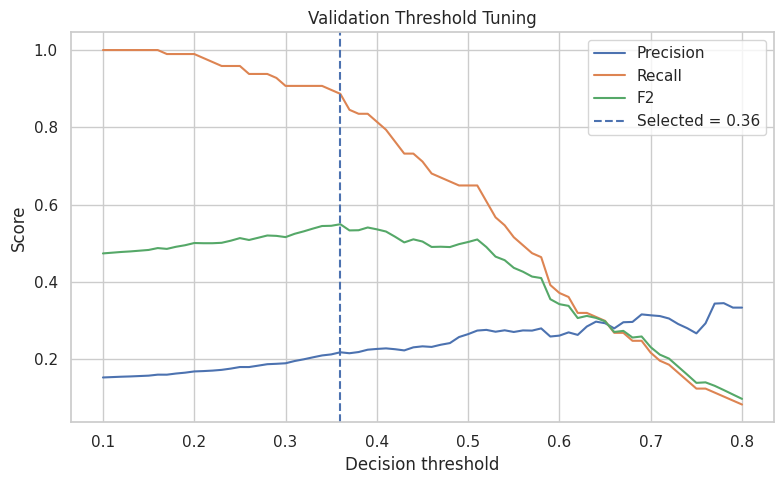

In [11]:
best_balanced_model = search.best_estimator_
val_prob = best_balanced_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.10, 0.81, 0.01)
threshold_rows = []
for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)
    threshold_rows.append({
        'threshold': threshold,
        'precision': precision_score(y_val, pred, zero_division=0),
        'recall': recall_score(y_val, pred, zero_division=0),
        'f2': fbeta_score(y_val, pred, beta=2, zero_division=0),
    })

threshold_results = pd.DataFrame(threshold_rows)
best_row = threshold_results.loc[threshold_results['f2'].idxmax()]
best_threshold = float(best_row['threshold'])

print(f'Selected threshold: {best_threshold:.2f}')
display(best_row.to_frame('validation_result'))

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(threshold_results['threshold'], threshold_results['precision'], label='Precision')
ax.plot(threshold_results['threshold'], threshold_results['recall'], label='Recall')
ax.plot(threshold_results['threshold'], threshold_results['f2'], label='F2')
ax.axvline(best_threshold, linestyle='--', label=f'Selected = {best_threshold:.2f}')
ax.set_xlabel('Decision threshold')
ax.set_ylabel('Score')
ax.set_title('Validation Threshold Tuning')
ax.legend()
plt.tight_layout()
plt.show()

## 11. Final model fit and untouched test-set evaluation

After selecting the hyperparameter and threshold, the model is refit on the combined training + validation data. The test set remains untouched until this step.

In [12]:
X_model = pd.concat([X_train, X_val], axis=0)
y_model = pd.concat([y_train, y_val], axis=0)

final_model = make_logistic_pipeline(
    class_weight='balanced',
    C=search.best_params_['model__C'],
)
final_model.fit(X_model, y_model)

tuned_test_prob = final_model.predict_proba(X_test)[:, 1]
tuned_metrics = evaluate_binary_model(y_test, tuned_test_prob, threshold=best_threshold)

comparison = pd.DataFrame([
    baseline_metrics,
    tuned_metrics,
], index=['Baseline LR (0.50)', 'Balanced + tuned threshold'])

display(comparison.T)

,Baseline LR (0.50),Balanced + tuned threshold
threshold,0.500,0.360
accuracy,0.852,0.502
balanced_accuracy,0.532,0.642
precision,0.583,0.211
recall_sensitivity,0.073,0.844
specificity,0.991,0.441
f1,0.130,0.338
f2,0.088,0.528
roc_auc,0.699,0.701
pr_auc,0.328,0.339


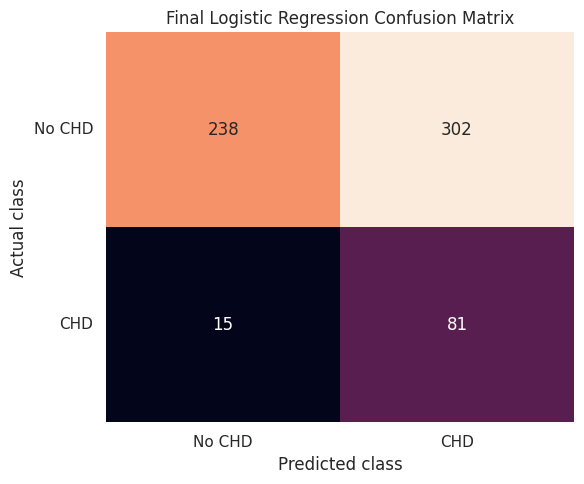

              precision    recall  f1-score   support

      No CHD       0.94      0.44      0.60       540
         CHD       0.21      0.84      0.34        96

    accuracy                           0.50       636
   macro avg       0.58      0.64      0.47       636
weighted avg       0.83      0.50      0.56       636



In [13]:
y_test_pred = (tuned_test_prob >= best_threshold).astype(int)
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, ax=ax)
ax.set_title('Final Logistic Regression Confusion Matrix')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
ax.set_xticklabels(['No CHD', 'CHD'])
ax.set_yticklabels(['No CHD', 'CHD'], rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_test_pred, target_names=['No CHD', 'CHD'], zero_division=0))

### Interpreting the operating-point trade-off

The tuned model should **not** be described as simply “more accurate.” Its overall accuracy is lower because the threshold was deliberately shifted toward identifying more CHD-positive cases. The model's underlying ranking performance changed only slightly (ROC-AUC 0.699 → 0.701), while sensitivity increased substantially (0.073 → 0.844). In a screening-style setting, this illustrates how the choice of classification threshold can prioritize missed-case reduction at the cost of more false positives.


## 12. ROC and Precision-Recall curves

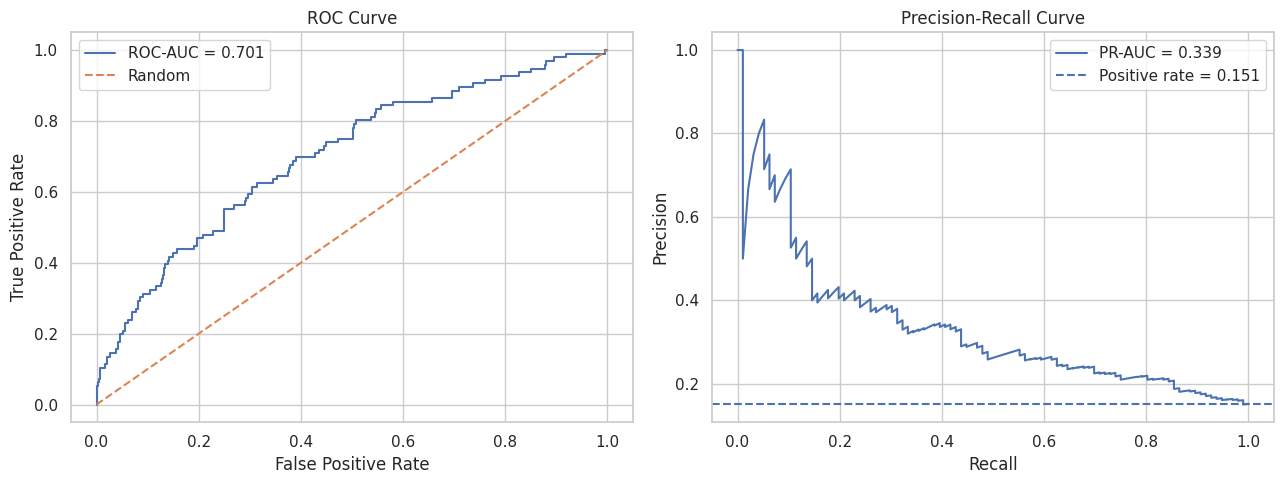

In [14]:
fpr, tpr, _ = roc_curve(y_test, tuned_test_prob)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, tuned_test_prob)
roc_auc = roc_auc_score(y_test, tuned_test_prob)
pr_auc = average_precision_score(y_test, tuned_test_prob)

fig, axes = plt.subplots(1, 2, figsize=(13,5))

axes[0].plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
axes[0].plot([0,1], [0,1], linestyle='--', label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()

axes[1].plot(recall_curve, precision_curve, label=f'PR-AUC = {pr_auc:.3f}')
axes[1].axhline(y_test.mean(), linestyle='--', label=f'Positive rate = {y_test.mean():.3f}')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

## 13. Interpreting Logistic Regression coefficients

Because the features are standardized, each coefficient represents the change in log-odds associated with a one-standard-deviation increase in that feature, holding other variables constant. `exp(coefficient)` is therefore a standardized odds ratio.

This is **model interpretation**, not proof of causation.

,feature,coefficient,standardized_odds_ratio
1,age,0.527,1.694
4,cigsPerDay,0.228,1.256
10,sysBP,0.225,1.253
0,male,0.186,1.204
14,glucose,0.121,1.129
7,prevalentHyp,0.108,1.114
9,totChol,0.097,1.101
6,prevalentStroke,0.082,1.086
5,BPMeds,0.059,1.061
8,diabetes,0.057,1.058


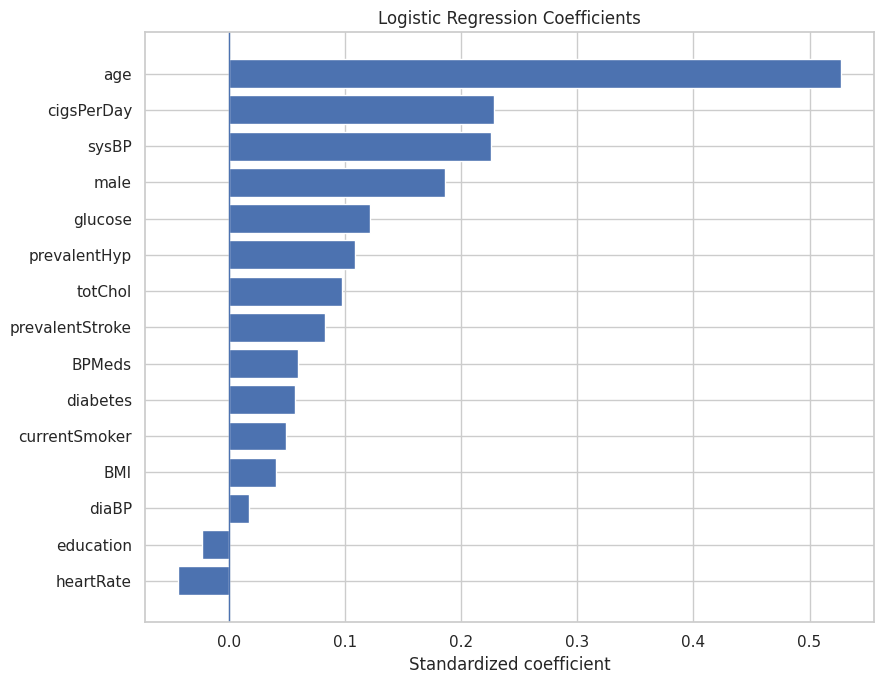

In [15]:
feature_names = X.columns
coefficients = final_model.named_steps['model'].coef_[0]

coef_table = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients,
    'standardized_odds_ratio': np.exp(coefficients),
})
coef_table['absolute_coefficient'] = coef_table['coefficient'].abs()
coef_table = coef_table.sort_values('absolute_coefficient', ascending=False)

display(coef_table.drop(columns='absolute_coefficient'))

plot_df = coef_table.sort_values('coefficient')
fig, ax = plt.subplots(figsize=(9,7))
ax.barh(plot_df['feature'], plot_df['coefficient'])
ax.axvline(0, linewidth=1)
ax.set_title('Logistic Regression Coefficients')
ax.set_xlabel('Standardized coefficient')
plt.tight_layout()
plt.show()

# Part II — K-Means Patient Segmentation

K-Means is used here to discover **patient profiles**, not to predict CHD labels. The CHD outcome is excluded from clustering and examined only afterward to understand how risk prevalence differs across the discovered segments.

## 14. Prepare features for clustering

In [16]:
cluster_imputer = SimpleImputer(strategy='median')
cluster_scaler = StandardScaler()

X_cluster_imputed = cluster_imputer.fit_transform(X_model)
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster_imputed)

print('Clustering matrix:', X_cluster_scaled.shape)

Clustering matrix: (3604, 15)


## 15. Choose k using silhouette score

,k,silhouette_score,inertia
0,2,0.211,"45,936.023"
1,3,0.215,"41,264.751"
2,4,0.143,"37,156.222"
3,5,0.153,"33,660.427"
4,6,0.173,"30,673.247"
5,7,0.173,"28,998.945"


Selected k = 3 based on the highest silhouette score.


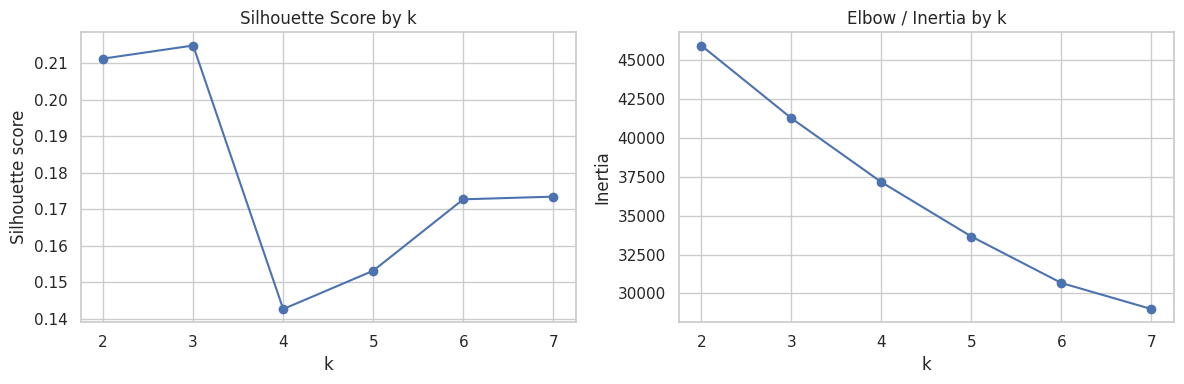

In [17]:
k_values = range(2, 8)
cluster_scores = []
cluster_inertia = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_cluster_scaled)
    cluster_scores.append(silhouette_score(X_cluster_scaled, labels))
    cluster_inertia.append(km.inertia_)

cluster_selection = pd.DataFrame({
    'k': list(k_values),
    'silhouette_score': cluster_scores,
    'inertia': cluster_inertia,
})
display(cluster_selection)

best_k = int(cluster_selection.loc[cluster_selection['silhouette_score'].idxmax(), 'k'])
print(f'Selected k = {best_k} based on the highest silhouette score.')

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(cluster_selection['k'], cluster_selection['silhouette_score'], marker='o')
axes[0].set_title('Silhouette Score by k')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Silhouette score')
axes[1].plot(cluster_selection['k'], cluster_selection['inertia'], marker='o')
axes[1].set_title('Elbow / Inertia by k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Inertia')
plt.tight_layout()
plt.show()

## 16. Fit K-Means and visualize with PCA

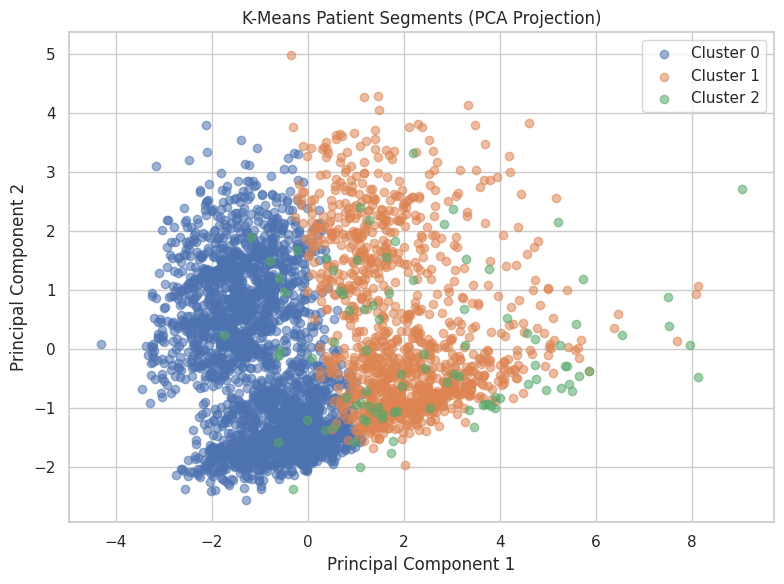

PCA variance explained: 0.338


In [18]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
cluster_labels = kmeans.fit_predict(X_cluster_scaled)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster_scaled)

fig, ax = plt.subplots(figsize=(8,6))
for cluster_id in sorted(np.unique(cluster_labels)):
    mask = cluster_labels == cluster_id
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.55, label=f'Cluster {cluster_id}')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_title('K-Means Patient Segments (PCA Projection)')
ax.legend()
plt.tight_layout()
plt.show()

print('PCA variance explained:', pca.explained_variance_ratio_.sum().round(3))

## 17. Profile the patient clusters

Cluster centers are transformed back to the original feature scale for easier interpretation. The CHD prevalence is then added as a **post-hoc descriptive statistic**; it was not used to create the clusters.

In [19]:
centers_original = cluster_scaler.inverse_transform(kmeans.cluster_centers_)
cluster_profiles = pd.DataFrame(centers_original, columns=X.columns)
cluster_profiles.index.name = 'Cluster'

model_with_clusters = X_model.copy()
model_with_clusters['Cluster'] = cluster_labels
model_with_clusters[target_col] = y_model.values

cluster_summary = model_with_clusters.groupby('Cluster').agg(
    patients=(target_col, 'size'),
    chd_prevalence=(target_col, 'mean'),
)

profile_features = ['age', 'currentSmoker', 'cigsPerDay', 'prevalentHyp', 'diabetes',
                    'totChol', 'sysBP', 'diaBP', 'BMI', 'glucose']

display(cluster_summary)
display(cluster_profiles[profile_features])

,patients,chd_prevalence
Cluster,,
0,2392,0.105
1,1116,0.236
2,96,0.365


,age,currentSmoker,cigsPerDay,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,glucose
Cluster,,,,,,,,,,
0,47.577,0.532,9.592,0.010,0.000,230.719,121.293,77.535,24.892,78.603
1,53.823,0.399,7.376,0.944,-0.000,248.849,154.802,94.013,27.667,80.790
2,54.677,0.365,6.417,0.531,1.000,245.240,146.990,86.651,28.016,167.063


## 18. Key findings

The dataset contains **4,240 participants**, while only **15.2%** of observations are positive for 10-year CHD. This class imbalance explains why overall accuracy alone is a poor measure of model usefulness.

### Classification results

| Metric | Baseline LR (0.50) | Balanced LR + tuned threshold (0.36) |
|---|---:|---:|
| Accuracy | 0.852 | 0.502 |
| Balanced accuracy | 0.532 | 0.642 |
| Precision | 0.583 | 0.211 |
| Recall / sensitivity | 0.073 | **0.844** |
| Specificity | 0.991 | 0.441 |
| F1 | 0.130 | 0.338 |
| F2 | 0.088 | **0.528** |
| ROC-AUC | 0.699 | 0.701 |
| PR-AUC | 0.328 | 0.339 |

The default 0.50 decision threshold produced high overall accuracy but identified only **7.3% of CHD-positive cases**. A class-balanced Logistic Regression model with a validation-selected threshold of **0.36** increased test recall to **84.4%**. This improvement came with an expected screening trade-off: precision decreased to **21.1%** and specificity to **44.1%**, meaning substantially more false-positive alerts.

The ROC-AUC changed only slightly from **0.699 to 0.701**, while PR-AUC increased from **0.328 to 0.339**. Therefore, most of the large change in sensitivity came from selecting a different operating threshold rather than a dramatic increase in the model's underlying discrimination. This is an important distinction when evaluating imbalanced classification systems.

The strongest positive standardized Logistic Regression coefficients were observed for **age** (standardized odds ratio ≈ 1.69), **cigarettes per day** (≈ 1.26), **systolic blood pressure** (≈ 1.25), **male sex** (≈ 1.20), and **glucose** (≈ 1.13). These values describe model associations in this dataset and should not be interpreted as causal effects.

### Patient segmentation results

Silhouette analysis selected **3 K-Means clusters** with a best silhouette score of approximately **0.215**, indicating useful but only modest separation between patient groups.

- **Cluster 0:** 2,392 patients; observed CHD prevalence **10.5%**. This was the largest and comparatively lower-risk group, with lower average blood pressure and glucose.
- **Cluster 1:** 1,116 patients; observed CHD prevalence **23.6%**. This group was characterized by very high hypertension prevalence (≈ 94.4%) and higher average systolic blood pressure (≈ 154.8 mmHg).
- **Cluster 2:** 96 patients; observed CHD prevalence **36.5%**. This small group had the highest observed CHD prevalence and was characterized by diabetes, markedly elevated average glucose (≈ 167.1 mg/dL), higher BMI, and elevated systolic blood pressure.

The first two PCA components explained about **33.8%** of the clustering variance, so the two-dimensional PCA plot should be treated as a visualization aid rather than proof of strong cluster separation.


## 19. Limitations and responsible use

- The dataset is observational, so associations should not be interpreted as causal effects.
- The positive CHD class is relatively uncommon, making threshold choice and minority-class metrics important.
- Median imputation is simple and reproducible, but it may not represent the best clinical missing-data strategy.
- Model performance on this teaching dataset does not establish external validity across hospitals, countries, age groups or demographic populations.
- Fairness across demographic groups is not fully assessed here.
- K-Means assumes roughly spherical clusters in standardized Euclidean space; real patient populations may have more complex structure.
- This project is educational and should not be used to make real clinical decisions.

## 20. Save reproducible model artifacts

In [20]:
artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)

joblib.dump(final_model, artifact_dir / 'logistic_regression_pipeline.joblib')
joblib.dump({
    'threshold': best_threshold,
    'feature_names': list(X.columns),
    'target': target_col,
}, artifact_dir / 'model_metadata.joblib')
joblib.dump({
    'imputer': cluster_imputer,
    'scaler': cluster_scaler,
    'kmeans': kmeans,
    'pca': pca,
}, artifact_dir / 'kmeans_segmentation.joblib')

print('Saved model artifacts to:', artifact_dir.resolve())

Saved model artifacts to: /content/artifacts


## Conclusion

This project demonstrates an end-to-end machine-learning workflow for an **imbalanced healthcare dataset**, combining interpretable supervised learning with unsupervised patient segmentation.

The main modelling lesson is that **overall accuracy is not enough**. At the default 0.50 threshold, Logistic Regression achieved **85.2% accuracy** but detected only **7.3% of CHD-positive cases**. After class balancing and validation-based threshold selection, sensitivity increased to **84.4%** and F2 to **0.528**, while specificity and precision decreased. This makes the final operating point more appropriate as an educational **screening-oriented example**, not as a clinical decision rule.

K-Means identified **three patient segments**. The highest-observed-risk cluster had **36.5% CHD prevalence** and showed a strong metabolic-risk profile, including diabetes and substantially elevated glucose, while another cluster was dominated by hypertension and high blood pressure. Because the silhouette score was modest, these clusters should be interpreted as exploratory patterns rather than sharply separated clinical phenotypes.

Overall, the project demonstrates the importance of **leakage-safe preprocessing, stratified validation, class-imbalance-aware evaluation, threshold selection, model interpretation, clustering validation, and responsible communication of healthcare ML results**.

### Skills demonstrated

`Python` · `pandas` · `NumPy` · `scikit-learn` · `Logistic Regression` · `K-Means` · `PCA` · `cross-validation` · `class imbalance` · `threshold tuning` · `ROC/PR analysis` · `model interpretation` · `reproducible pipelines`

> **Responsible-use note:** This is an educational portfolio project based on a teaching dataset. It is not clinically validated and must not be used for diagnosis or patient-level medical decisions.
